In [10]:
import pandas as pd

dataframe = pd.read_csv("extracted_data/dataset.csv")
print("Rows, Columns:", dataframe.shape)
print("Column names:", list(dataframe.columns))
print(dataframe.head())
print("Languages count:", dataframe.iloc[:, 1].nunique())
print(dataframe.iloc[:, 1].value_counts())

Rows, Columns: (22000, 2)
Column names: ['Text', 'language']
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
Languages count: 22
language
Estonian      1000
Swedish       1000
Thai          1000
Tamil         1000
Dutch         1000
Japanese      1000
Turkish       1000
Latin         1000
Urdu          1000
Indonesian    1000
Portugese     1000
French        1000
Chinese       1000
Korean        1000
Hindi         1000
Spanish       1000
Pushto        1000
Persian       1000
Romanian      1000
Russian       1000
English       1000
Arabic        1000
Name: count, dtype: int64


In [12]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [13]:
import glob
import os
import zipfile

for zip_path in glob.glob("*.zip"):
    with zipfile.ZipFile(zip_path) as zip_file:
        zip_file.extractall("extracted_data")

candidate_files = (
    glob.glob("extracted_data/**/*.csv", recursive=True)
    + glob.glob("extracted_data/**/*.xlsx", recursive=True)
    + glob.glob("*.csv")
    + glob.glob("*.xlsx")
)
candidate_files = [path for path in candidate_files if os.path.isfile(path)]
print("Files found:", candidate_files)

FILE_PATH = candidate_files[0]  # thappa file eduthuchuna idha manual-ah maathunga
SAMPLES_PER_LANGUAGE = 500
MAX_LENGTH = 100
RANDOM_STATE = 42
print("Using file:", FILE_PATH)

if FILE_PATH.lower().endswith((".xlsx", ".xls")):
    dataframe = pd.read_excel(FILE_PATH)
else:
    dataframe = pd.read_csv(FILE_PATH)
print("Columns:", list(dataframe.columns))

# Column names different-ah irundha auto-detect pannum
text_column = "text" if "text" in dataframe.columns else dataframe.columns[0]
label_column = None
for candidate in ["labels", "label", "language", "Language"]:
    if candidate in dataframe.columns:
        label_column = candidate
        break
if label_column is None:
    label_column = dataframe.columns[1]
print("Text column:", text_column, "| Label column:", label_column)

dataframe = dataframe[[text_column, label_column]]
dataframe.columns = ["text", "language"]

print("Missing values:\n", dataframe.isnull().sum())
dataframe = dataframe.dropna()
dataframe = dataframe.drop_duplicates()

# Manageable subset
dataframe = (
    dataframe.groupby("language", group_keys=False)
    .apply(lambda group: group.sample(min(len(group), SAMPLES_PER_LANGUAGE), random_state=RANDOM_STATE))
    .reset_index(drop=True)
)
print("Subset size:", len(dataframe), "| Languages:", dataframe["language"].nunique())


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[0-9]+", " ", text)
    text = re.sub(r"[!\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


dataframe["clean_text"] = dataframe["text"].apply(clean_text)
dataframe = dataframe[dataframe["clean_text"].str.len() > 0]


Files found: ['extracted_data/dataset.csv']
Using file: extracted_data/dataset.csv
Columns: ['Text', 'language']
Text column: Text | Label column: language
Missing values:
 text        0
language    0
dtype: int64
Subset size: 11000 | Languages: 22


/tmp/ipykernel_801/1275679703.py:51: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(min(len(group), SAMPLES_PER_LANGUAGE), random_state=RANDOM_STATE))


In [14]:
# Tokenizing and splitting data for training and testing
tokenizer = Tokenizer(char_level=True, oov_token="<OOV>")
tokenizer.fit_on_texts(dataframe["clean_text"])
vocabulary_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocabulary_size)

sequences = tokenizer.texts_to_sequences(dataframe["clean_text"])
padded_sequences = pad_sequences(sequences, maxlen=MAX_LENGTH, padding="post", truncating="post")

label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(dataframe["language"])
number_of_classes = len(label_encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences, encoded_labels,
    test_size=0.2, stratify=encoded_labels, random_state=RANDOM_STATE
)

Vocabulary size: 6196


In [5]:
model = Sequential([
    Embedding(input_dim=vocabulary_size, output_dim=64),
    Bidirectional(LSTM(128)),
    Dropout(0.4),
    Dense(number_of_classes, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, MAX_LENGTH))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       396,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       197,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 599,830 (2.29 MB)

 Trainable params: 599,830 (2.29 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stopping = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
)

predicted_probabilities = model.predict(X_test)
y_predicted = np.argmax(predicted_probabilities, axis=1)

print("\nTest Accuracy:", accuracy_score(y_test, y_predicted))
print("\nClassification Report (precision, recall, f1-score):\n")
print(classification_report(y_test, y_predicted, target_names=label_encoder.classes_))


Epoch 1/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.2384 - loss: 2.2288 - val_accuracy: 0.4636 - val_loss: 1.6544
Epoch 2/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4508 - loss: 1.5407 - val_accuracy: 0.5307 - val_loss: 1.3103
Epoch 3/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5465 - loss: 1.3161 - val_accuracy: 0.6034 - val_loss: 1.1266
Epoch 4/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5997 - loss: 1.2163 - val_accuracy: 0.6216 - val_loss: 1.1173
Epoch 5/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6409 - loss: 1.0747 - val_accuracy: 0.6761 - val_loss: 0.9725
Epoch 6/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6614 - loss: 1.0055 - val_accuracy: 0.7011 - val_loss: 0.8826
Epoch 7/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6806 - loss: 0.9429 - val_accuracy: 0.7307 - val_loss: 0.7807
Epoch 8/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7275 - loss: 0.7972 - val_acc

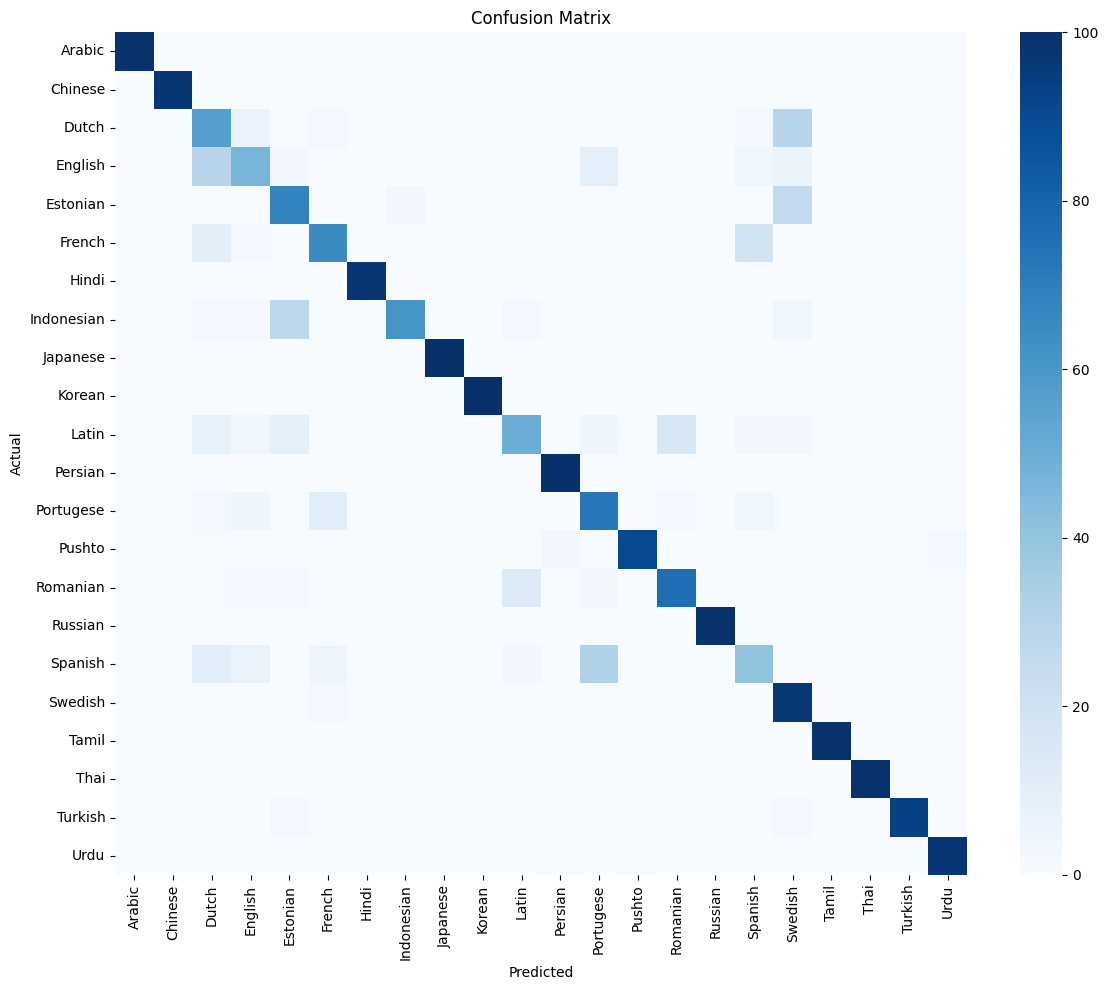


Predictions on unseen samples:
The weather is very nice today and we are going to the park.
  -> Dutch (52.61%)

Je voudrais réserver une table pour deux personnes ce soir.
  -> Pushto (40.50%)

Ich habe gestern einen interessanten Film im Kino gesehen.
  -> Dutch (43.96%)

Me gusta mucho aprender cosas nuevas todos los días.
  -> Pushto (29.63%)

Questa mattina ho bevuto un caffè molto buono al bar.
  -> Pushto (34.20%)



In [7]:
matrix = confusion_matrix(y_test, y_predicted)
plt.figure(figsize=(12, 10))
sns.heatmap(matrix, annot=number_of_classes <= 15, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


def predict_language(sentence):
    cleaned = clean_text(sentence)
    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(sequence, maxlen=MAX_LENGTH, padding="post", truncating="post")
    probabilities = model.predict(padded, verbose=0)[0]
    best_index = int(np.argmax(probabilities))
    return label_encoder.classes_[best_index], float(probabilities[best_index])


unseen_samples = [
    "The weather is very nice today and we are going to the park.",
    "Je voudrais réserver une table pour deux personnes ce soir.",
    "Ich habe gestern einen interessanten Film im Kino gesehen.",
    "Me gusta mucho aprender cosas nuevas todos los días.",
    "Questa mattina ho bevuto un caffè molto buono al bar.",
]

print("\nPredictions on unseen samples:")
for sample in unseen_samples:
    language, confidence = predict_language(sample)
    print(f"{sample}\n  -> {language} ({confidence:.2%})\n")
